# Практическое занятие №2. Прогнозирование оттока клиентов телеком-оператора

**Датасет:** Telco Customer Churn (IBM), взят из репозитория [plotly/datasets](https://github.com/plotly/datasets).

**Задача:** по данным о клиенте (услуги, тип договора, способ оплаты, сколько платит и т.д.) предсказать, уйдёт он от оператора или нет (столбец `Churn`). Это задача бинарной классификации.

В этой работе использую готовый пайплайн предобработки: численные признаки масштабирую, категориальные кодирую через One-Hot Encoding. Основная модель - CatBoostClassifier. Также сравню её с Logistic Regression и Random Forest, а в конце проверю, что даст SMOTE.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score, roc_curve,
    f1_score, recall_score
)

from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='deep')


## Этап 1. Загрузка и подготовка данных

### 1. Загрузка датасета


In [2]:
url = 'https://raw.githubusercontent.com/plotly/datasets/master/telco-customer-churn-by-IBM.csv'
df = pd.read_csv(url)

print('Размерность таблицы:', df.shape)
df.head()


Размерность таблицы: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2. Проверка столбца TotalCharges и целевой переменной

В `TotalCharges` встречаются пустые строки. Сначала превращаю этот столбец в числовой, а затем заполняю пропуски нулями. Идентификатор клиента `customerID` не использую как признак: это уникальный номер, который не описывает клиента.


In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce')
print('Пропусков в TotalCharges:', df['TotalCharges'].isna().sum())
df['TotalCharges'] = df['TotalCharges'].fillna(0)

df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})
print('Доля ушедших клиентов:', round(df['Churn'].mean(), 3))


Пропусков в TotalCharges: 11
Доля ушедших клиентов: 0.265


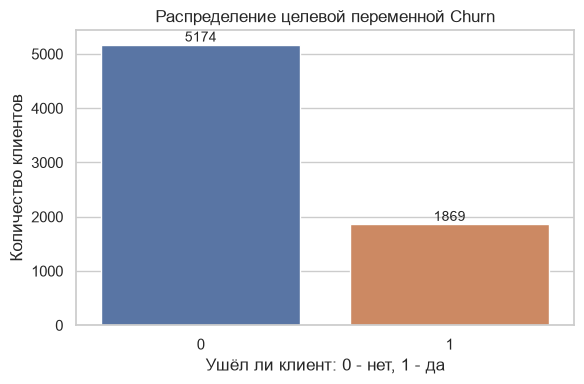

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Churn', hue='Churn', legend=False,
              palette=['#4C72B0', '#DD8452'], ax=ax)
for patch in ax.patches:
    ax.annotate(f'{int(patch.get_height())}',
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha='center', va='bottom', fontsize=10)
ax.set_title('Распределение целевой переменной Churn')
ax.set_xlabel('Ушёл ли клиент: 0 - нет, 1 - да')
ax.set_ylabel('Количество клиентов')
plt.tight_layout()
plt.show()


**Вывод:** ушедших клиентов заметно меньше, чем оставшихся. Поэтому одной accuracy недостаточно: дальше смотрю на ROC-AUC, F1 и Recall для класса 1. Разбиение делаю со стратификацией, чтобы доля ушедших в train и test сохранилась.

## Этап 2. Разделение на признаки и целевую переменную

### 3. X, y и train/test split


In [5]:
X = df.drop(columns=['Churn', 'customerID'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'string']).columns.tolist()

print('X:', X.shape)
print('Train:', X_train.shape, '| доля Churn =', round(y_train.mean(), 3))
print('Test: ', X_test.shape, '| доля Churn =', round(y_test.mean(), 3))
print('\nЧисленные признаки:', numeric_features)
print('\nКатегориальные признаки:', categorical_features)


X: (7043, 19)
Train: (5634, 19) | доля Churn = 0.265
Test:  (1409, 19) | доля Churn = 0.265

Численные признаки: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Категориальные признаки: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Этап 3. Pipeline и CatBoost

### 4. ColumnTransformer

Численные признаки масштабирую с помощью `StandardScaler`, а категориальные кодирую `OneHotEncoder`. Параметр `handle_unknown='ignore'` нужен на случай, если в тесте встретится категория, которой не было в train.


In [6]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
        ],
        remainder='drop'
    )

preprocessor = make_preprocessor()
preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

### 5. Pipeline и подбор параметров

В одном Pipeline находятся предобработка и модель, поэтому при кросс-валидации преобразования обучаются только на тренировочной части каждого фолда. Для CatBoost подбираю `depth` и `learning_rate` по ROC-AUC.


In [7]:
catboost_pipeline = Pipeline(steps=[
    ('preprocessor', make_preprocessor()),
    ('model', CatBoostClassifier(
        iterations=100,
        verbose=0,
        random_state=RANDOM_STATE,
        thread_count=1,
        allow_writing_files=False
    ))
])

param_grid = {
    'model__depth': [4, 6],
    'model__learning_rate': [0.05, 0.1]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(
    estimator=catboost_pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

grid_search.fit(X_train, y_train)

print('Лучшие параметры:', grid_search.best_params_)
print(f'Лучший средний ROC-AUC по CV: {grid_search.best_score_:.4f}')


Лучшие параметры: {'model__depth': 4, 'model__learning_rate': 0.05}
Лучший средний ROC-AUC по CV: 0.8496


In [8]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results[['params', 'mean_test_score', 'std_test_score']].sort_values(
    'mean_test_score', ascending=False
).rename(columns={
    'params': 'Параметры',
    'mean_test_score': 'Средний ROC-AUC',
    'std_test_score': 'Стандартное отклонение'
}).round(4)


,Параметры,Средний ROC-AUC,Стандартное отклонение
0,"{'model__depth': 4, 'model__learning_rate': 0.05}",0.8496,0.0089
1,"{'model__depth': 4, 'model__learning_rate': 0.1}",0.8484,0.0090
2,"{'model__depth': 6, 'model__learning_rate': 0.05}",0.8478,0.0088
3,"{'model__depth': 6, 'model__learning_rate': 0.1}",0.8424,0.0075


## Этап 4. Качество CatBoost на тестовой выборке

### 6. Classification report и ROC-AUC


In [9]:
best_catboost = grid_search.best_estimator_
y_pred_catboost = best_catboost.predict(X_test)
y_proba_catboost = best_catboost.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_catboost,
                            target_names=['Остался (0)', 'Ушёл (1)']))

roc_auc_catboost = roc_auc_score(y_test, y_proba_catboost)
f1_catboost = f1_score(y_test, y_pred_catboost)
recall_catboost = recall_score(y_test, y_pred_catboost)

print(f'ROC-AUC (CatBoost): {roc_auc_catboost:.4f}')
print(f'F1     (CatBoost): {f1_catboost:.4f}')
print(f'Recall (CatBoost): {recall_catboost:.4f}')


              precision    recall  f1-score   support

 Остался (0)       0.84      0.91      0.87      1035
    Ушёл (1)       0.68      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.71      0.73      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC (CatBoost): 0.8466
F1     (CatBoost): 0.5857
Recall (CatBoost): 0.5160


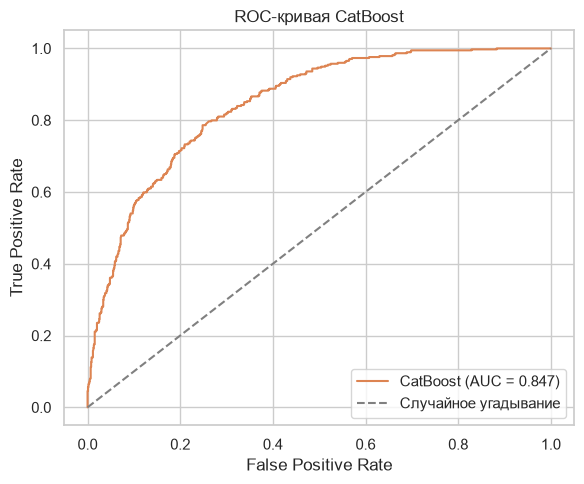

In [10]:
fpr, tpr, _ = roc_curve(y_test, y_proba_catboost)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color='#DD8452', label=f'CatBoost (AUC = {roc_auc_catboost:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Случайное угадывание')
ax.set_title('ROC-кривая CatBoost')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


### 7. Важность признаков

После One-Hot Encoding один исходный категориальный признак превращается в несколько столбцов. На графике ниже показаны 15 наиболее важных получившихся признаков.


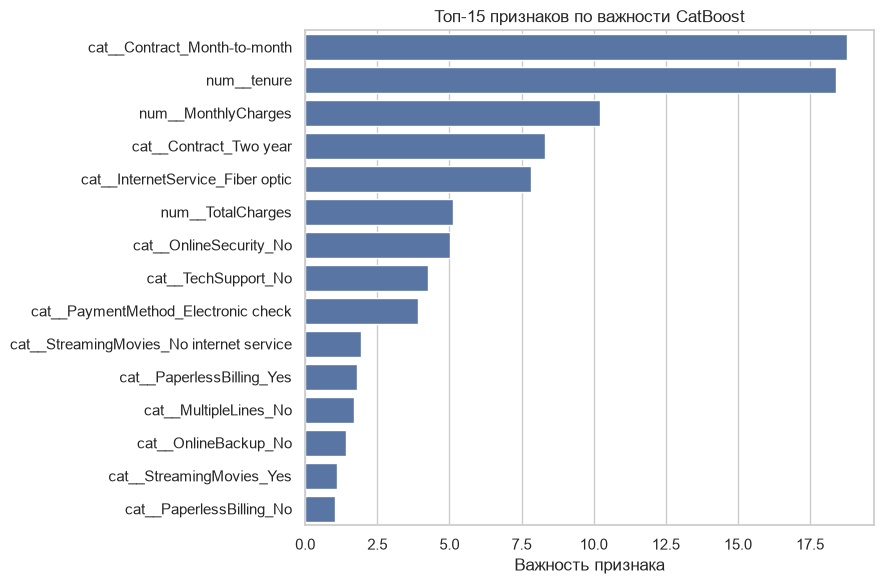

cat__Contract_Month-to-month                18.778
num__tenure                                 18.401
num__MonthlyCharges                         10.208
cat__Contract_Two year                       8.298
cat__InternetService_Fiber optic             7.839
num__TotalCharges                            5.128
cat__OnlineSecurity_No                       5.027
cat__TechSupport_No                          4.271
cat__PaymentMethod_Electronic check          3.900
cat__StreamingMovies_No internet service     1.925
cat__PaperlessBilling_Yes                    1.780
cat__MultipleLines_No                        1.689
cat__OnlineBackup_No                         1.428
cat__StreamingMovies_Yes                     1.117
cat__PaperlessBilling_No                     1.023
dtype: float64

In [11]:
feature_names = best_catboost.named_steps['preprocessor'].get_feature_names_out()
importances = pd.Series(
    best_catboost.named_steps['model'].feature_importances_,
    index=feature_names
).sort_values(ascending=False)

top15 = importances.head(15)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=top15.values, y=top15.index, color='#4C72B0', ax=ax)
ax.set_title('Топ-15 признаков по важности CatBoost')
ax.set_xlabel('Важность признака')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

top15.round(3)


## Задания со звёздочкой

### 1. Сравнение Logistic Regression, Random Forest и CatBoost

Все модели получают одинаковую предобработку и одинаковое train/test-разбиение. Для CatBoost беру лучшую модель из GridSearchCV.


In [12]:
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', make_preprocessor()),
    ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

rf_pipeline = Pipeline(steps=[
    ('preprocessor', make_preprocessor()),
    ('model', RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

models = {
    'Logistic Regression': logreg_pipeline,
    'Random Forest': rf_pipeline,
    'CatBoost': best_catboost
}

comparison_rows = []
predictions = {}

for name, model in models.items():
    if name != 'CatBoost':
        model.fit(X_train, y_train)

    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    predictions[name] = (prediction, probability)

    comparison_rows.append({
        'Модель': name,
        'ROC-AUC': roc_auc_score(y_test, probability),
        'F1 (класс 1)': f1_score(y_test, prediction),
        'Recall (класс 1)': recall_score(y_test, prediction)
    })

comparison = pd.DataFrame(comparison_rows).sort_values('ROC-AUC', ascending=False)
comparison.round(4)


,Модель,ROC-AUC,F1 (класс 1),Recall (класс 1)
2,CatBoost,0.8466,0.5857,0.5160
0,Logistic Regression,0.8421,0.6040,0.5588
1,Random Forest,0.8419,0.5797,0.5107


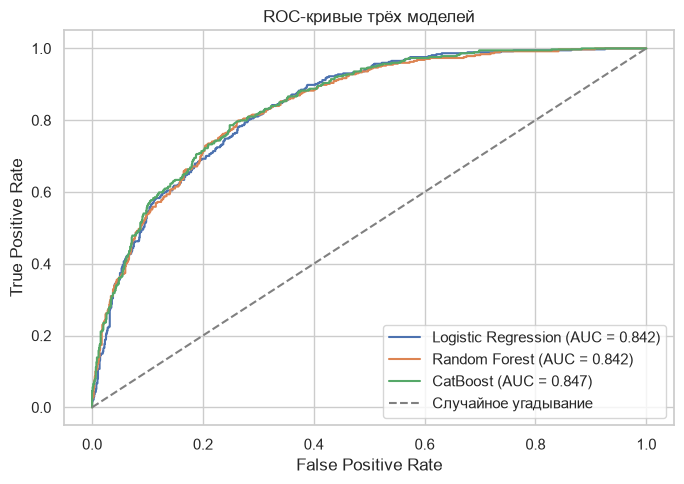

Лучший ROC-AUC: CatBoost (0.8466)
Лучший F1: Logistic Regression (0.6040)


In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, (_, probability) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, probability)
    auc = roc_auc_score(y_test, probability)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Случайное угадывание')
ax.set_title('ROC-кривые трёх моделей')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

best_by_auc = comparison.iloc[0]
best_by_f1 = comparison.sort_values('F1 (класс 1)', ascending=False).iloc[0]
print(f"Лучший ROC-AUC: {best_by_auc['Модель']} ({best_by_auc['ROC-AUC']:.4f})")
print(f"Лучший F1: {best_by_f1['Модель']} ({best_by_f1['F1 (класс 1)']:.4f})")


**Вывод по моделям:** сравнение делаю не только по ROC-AUC, но и по F1 для ушедших клиентов. ROC-AUC показывает, насколько хорошо модель ранжирует клиентов по риску ухода, а F1 учитывает баланс между Precision и Recall. У модели с наибольшим ROC-AUC можно использовать вероятности как риск-скор; модель с наибольшим F1 лучше находит компромисс при стандартном пороге 0.5.

### 2. SMOTE и Recall

SMOTE применяю только внутри обучающего Pipeline. Это важно: синтетические наблюдения должны строиться только по train-части, иначе информация из test попадёт в обучение.


In [14]:
best_catboost_params = {
    key.replace('model__', ''): value
    for key, value in grid_search.best_params_.items()
}

smote_pipeline = ImbPipeline(steps=[
    ('preprocessor', make_preprocessor()),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('model', CatBoostClassifier(
        iterations=100,
        verbose=0,
        random_state=RANDOM_STATE,
        thread_count=1,
        allow_writing_files=False,
        **best_catboost_params
    ))
])

smote_pipeline.fit(X_train, y_train)
y_pred_smote = smote_pipeline.predict(X_test)
y_proba_smote = smote_pipeline.predict_proba(X_test)[:, 1]

recall_smote = recall_score(y_test, y_pred_smote)
f1_smote = f1_score(y_test, y_pred_smote)
roc_auc_smote = roc_auc_score(y_test, y_proba_smote)

smote_comparison = pd.DataFrame([
    {'Вариант': 'CatBoost без SMOTE', 'ROC-AUC': roc_auc_catboost,
     'F1 (класс 1)': f1_catboost, 'Recall (класс 1)': recall_catboost},
    {'Вариант': 'CatBoost + SMOTE', 'ROC-AUC': roc_auc_smote,
     'F1 (класс 1)': f1_smote, 'Recall (класс 1)': recall_smote}
])

smote_comparison.round(4)


,Вариант,ROC-AUC,F1 (класс 1),Recall (класс 1)
0,CatBoost без SMOTE,0.8466,0.5857,0.5160
1,CatBoost + SMOTE,0.8416,0.6284,0.7166


In [15]:
delta_recall = recall_smote - recall_catboost
print(classification_report(y_test, y_pred_smote,
                            target_names=['Остался (0)', 'Ушёл (1)']))
print(f'Recall без SMOTE: {recall_catboost:.4f}')
print(f'Recall со SMOTE:  {recall_smote:.4f}')
print(f'Изменение Recall: {delta_recall:+.4f}')

if delta_recall > 0:
    print('SMOTE увеличил Recall: модель стала находить больше ушедших клиентов.')
else:
    print('SMOTE не увеличил Recall в этом разбиении. Это тоже нормальный результат: эффект зависит от данных и модели.')


              precision    recall  f1-score   support

 Остался (0)       0.89      0.80      0.84      1035
    Ушёл (1)       0.56      0.72      0.63       374

    accuracy                           0.78      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.78      0.78      1409

Recall без SMOTE: 0.5160
Recall со SMOTE:  0.7166
Изменение Recall: +0.2005
SMOTE увеличил Recall: модель стала находить больше ушедших клиентов.


## Итоги

1. Данные разделены на train/test с `stratify=y`, поэтому доля ушедших клиентов сохранена в обеих выборках.
2. Предобработка и CatBoost объединены в Pipeline. Численные признаки масштабируются, категориальные превращаются в dummy-признаки через One-Hot Encoding.
3. Для CatBoost выполнен GridSearchCV по двум параметрам, а качество на тесте оценено по classification report и ROC-AUC.
4. Построен график важности признаков CatBoost.
5. Дополнительно сравнены Logistic Regression, Random Forest и CatBoost, а также проверено влияние SMOTE на Recall класса «ушёл».
